In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## 1. High Level View

In this part, I will add the dataset to this google colab, present the first five rows and describe the dataset.

In [5]:
df = pd.read_csv("2016.csv")
df.head(5)

,Country,Region,Happiness Rank,Happiness Score,Lower Confidence Interval,Upper Confidence Interval,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Denmark,Western Europe,1,7.526,7.460,7.592,1.44178,1.16374,0.79504,0.57941,0.44453,0.36171,2.73939
1,Switzerland,Western Europe,2,7.509,7.428,7.590,1.52733,1.14524,0.86303,0.58557,0.41203,0.28083,2.69463
2,Iceland,Western Europe,3,7.501,7.333,7.669,1.42666,1.18326,0.86733,0.56624,0.14975,0.47678,2.83137
3,Norway,Western Europe,4,7.498,7.421,7.575,1.57744,1.12690,0.79579,0.59609,0.35776,0.37895,2.66465
4,Finland,Western Europe,5,7.413,7.351,7.475,1.40598,1.13464,0.81091,0.57104,0.41004,0.25492,2.82596


Based on the first 5 rows of the dataset, we can observe that it provides different statistics on selected countries. Each row represents a country, followed by columns that describe its respective statistics, such as happiness score, life expectancy relative to happiness score, and where the country ranks on the happiness scale compared to the rest of the dataset. This dataset could be useful for interpreting whether happiness scores are associated with other statistics in the dataset.

## 2. Preliminary Exploration

The two preliminary exploration tasks I will be performing are identifying potential outliers in Happiness Scores and calculating average Happiness Scores by region to better understand what is present in the dataset. Based on my initial examination, the dataset appears complete, and no additional cleaning is necessary for my planned analysis.

In [6]:
df_dimensions = df.shape
df_dimensions

(157, 13)

In [7]:
data_types = df.dtypes
data_types

,0
Country,object
Region,object
Happiness Rank,int64
Happiness Score,float64
Lower Confidence Interval,float64
Upper Confidence Interval,float64
Economy (GDP per Capita),float64
Family,float64
Health (Life Expectancy),float64
Freedom,float64


In [8]:
lowest_happiness_score = df["Happiness Score"].min()
highest_happiness_score = df["Happiness Score"].max()
print("Lowest Happiness Score :", lowest_happiness_score)
print("Highest Happiness Score :", highest_happiness_score)

Lowest Happiness Score : 2.905
Highest Happiness Score : 7.526


In [9]:
df_stats = df.describe()
df_stats["Happiness Score"]

,Happiness Score
count,157.000000
mean,5.382185
std,1.141674
min,2.905000
25%,4.404000
50%,5.314000
75%,6.269000
max,7.526000


In [10]:
q1 = df_stats["Happiness Score"].loc["25%"]
q3 = df_stats["Happiness Score"].loc["75%"]
iqr = q3 - q1
lower_fence = q1 - (1.5 * iqr)
upper_fence = q3 + (1.5 * iqr)
print(iqr)
print(lower_fence)
print(upper_fence)

1.8650000000000002
1.6064999999999996
9.066500000000001


For my first exploration task, I described the data to observe the happiness score in the data and see if there were any outliers related to happiness score. I investigated to see if there were any outliers to determine if any countries were extremely happy or extremely unhappy compared to the rest of the data set. After calculating the IQR, finding the lower and upper fences of the dataset, we can determine that there are no outliers based on happiness in this dataset.

In [11]:
average_region_happiness = df.groupby("Region")["Happiness Score"].mean().sort_values(ascending=False)
average_region_happiness

,Happiness Score
Region,
Australia and New Zealand,7.323500
North America,7.254000
Western Europe,6.685667
Latin America and Caribbean,6.101750
Eastern Asia,5.624167
Middle East and Northern Africa,5.386053
Central and Eastern Europe,5.370690
Southeastern Asia,5.338889
Southern Asia,4.563286


For my second exploration task, I wanted to calculate the average happiness score by region. Based on this data, we can observe that Australia and New Zealand have the highest happiness score at 7.323500 and Sub-Saharan Africa has the lowest happiness score at 4.136421. This could help identify geological differences in reported happiness that could, in turn, motivate further investigation.


## 3. Defining Research Objectives

### Objective 1: Generosity and Economy
Do countries with higher Generosity values also tend to have higher Economy (GDP per Capita) values?

### Objective 2: Region and Government Trust
Do average Trust (Government Corruption) values differ across geographical regions?

### Objective 3: Family and Happiness Rank
Do countries with higher Family values tend to have better happiness rankings (lower numerical Happiness Rank values)?


## 4. Present Your Findings

For Objective #1, I will be using a scatterplot because both Generosity and Economy are numerical variables. In this scatterplot, each dot will represent one country, and we will be able to examine the values to see if there is an association between the two variables.

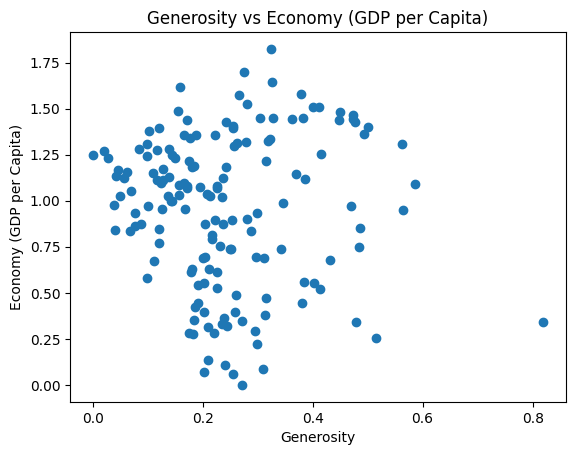

In [13]:
plt.scatter(df["Generosity"], df["Economy (GDP per Capita)"])
plt.xlabel("Generosity")
plt.ylabel("Economy (GDP per Capita)")
plt.title("Generosity vs Economy (GDP per Capita)")
plt.show()


In [14]:
df[["Generosity", "Economy (GDP per Capita)"]].corr()

,Generosity,Economy (GDP per Capita)
Generosity,1.000000,-0.025531
Economy (GDP per Capita),-0.025531,1.000000


Based on the scatterplot seen above, as well as the numerical correlation analysis, we can observe that there is essentially no linear correlation between generosity and economy. The correlation coefficient that was identified was r = -0.0255, and because it is extremely close to zero, it indicates no linear correlation between the two.

For Objective #2, I will be using a bar chart to determine whether average government-trust-related values differ depending on the region. The reason I will be using a bar chart is that it is appropriate for this comparison, as it allows me to compare values across categories. In this objective, each bar will represent a geographical region, and its height will represent the average government-trust-related value for that region.

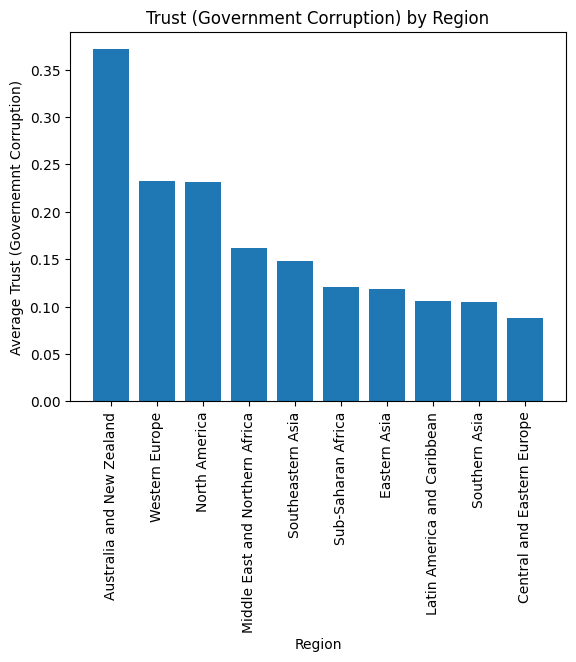

In [22]:
regional_trust = df.groupby("Region")["Trust (Government Corruption)"].mean().sort_values(ascending = False)

plt.bar(regional_trust.index, regional_trust.values)
plt.xlabel("Region")
plt.xticks(rotation=90)
plt.ylabel("Average Trust (Government Corruption)")
plt.title("Trust (Government Corruption) by Region")
plt.show()



Based on the bar graph above, we can observe that average Trust (Government Corruption) values differ across regions. The highest average value was in the Australia and New Zealand region, while the lowest was in the Central and Eastern Europe region. These differences suggest that average Trust (Government Corruption) values vary across geographical regions, as my research question proposed.

For Objective #3, I will be using a scatterplot to determine if countries with higher Family values tend to have better happiness rankings (lower numerical Happiness Rank values). I will be using a scatterplot because I will be comparing two numerical variables, and the scatterplot will help us observe whether there is an association between them.

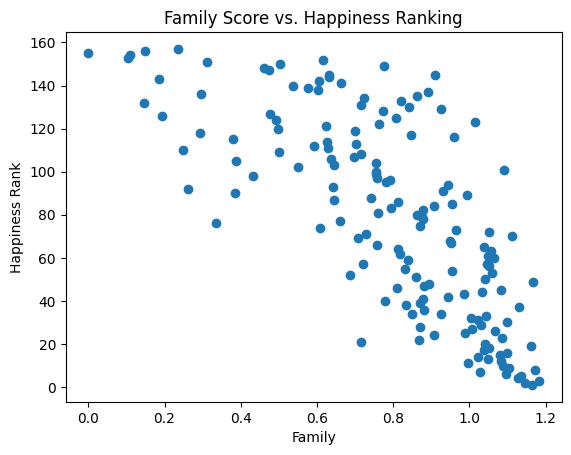

In [24]:
plt.scatter(df["Family"], df["Happiness Rank"])
plt.xlabel("Family")
plt.ylabel("Happiness Rank")
plt.title("Family Score vs. Happiness Ranking")
plt.show()

In [25]:
df[["Family", "Happiness Rank"]].corr()

,Family,Happiness Rank
Family,1.000000,-0.733276
Happiness Rank,-0.733276,1.000000


Based on the scatterplot, we can observe a strong negative linear association between Family values and Happiness Rank. Countries with higher Family values tend to have lower numerical Happiness Rank values, indicating better happiness rankings. The Pearson correlation coefficient was r = -0.7333, which supports the observation that countries with higher Family values generally tend to have better happiness rankings.

## 5. Ethics

One ethical concern that could be observed in the dataset is bias and misleading interpretations of government corruption. This could be a potential ethical concern, as this variable likely doesn't fully capture the complexity of corruption perceptions across different countries. These types of misinterpretations could create negative stereotypes about countries or regions.